# Assignment 01: Variational Autoencoder

In this assignment you implement a variational autoencoder (VAE) and train it on a small subset of MNIST: the digits 0, 1, 2, 3, 4 as gray images of 32 x 32 pixels, with 100 training images and 1000 test images per digit. The images come without labels.

**Do not modify this notebook.** It runs the code that you write, measures the trained model, and saves the results.

You write the files in the `code` folder:

| File | What you write |
|---|---|
| `code/myinfo.py` | your name and student ID |
| `code/mymodel.py` | the VAE: encoder, reparameterization, decoder |
| `code/myoptim.py` | batch size, number of epochs, optimizer |
| `code/mytrain.py` | loss function, training for one epoch |
| `code/mysample.py` | generation of new images |

Every part to write is marked with `TODO`, and the docstring of each function specifies its inputs and outputs. Keep these interfaces unchanged.

The files in the `util` folder are provided; do not modify them:

| File | What it provides |
|---|---|
| `util/data.py` | `get_dataset("train")` and `get_dataset("test")`: the training and the test images |
| `util/result.py` | `evaluate`: FID and reconstruction error of the trained model on the test images; `save`: writes them to a file |

The data files in the `data` folder are created by `util/prepare_data_mnist.py`.

Run all the cells from top to bottom (*Restart* and *Run All*). The notebook saves:

| File | Content |
|---|---|
| `train/loss.png`, `train/model.pt` | training curves, trained model |
| `sample/sample.png` | images generated by the trained model |
| `result/reconstruction.png` | test images and their reconstructions |
| `result/result_<student ID>_<name>.csv` | FID and reconstruction error |

## Setup

In [3]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# The notebook is in the project folder, next to the folders code, util, data
ROOT = Path.cwd()
assert (ROOT / "code").is_dir() and (ROOT / "util").is_dir(), (
    f"run this notebook from the project folder, which contains code and util (now in {ROOT})")

# Make the files of code (yours) and util (provided) importable
for folder in ("code", "util"):
    if str(ROOT / folder) not in sys.path:
        sys.path.insert(0, str(ROOT / folder))

# Folders for the files saved by the notebook
TRAIN_DIR, SAMPLE_DIR, RESULT_DIR = ROOT / "train", ROOT / "sample", ROOT / "result"
for folder in (TRAIN_DIR, SAMPLE_DIR, RESULT_DIR):
    folder.mkdir(exist_ok=True)

SEED = 0
torch.manual_seed(SEED)

# GPU of NVIDIA (cuda) or of an Apple silicon Mac (mps) if there is one, else the CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"torch   : {torch.__version__}")
print(f"device  : {device}")
print(f"project : {ROOT}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
torch   : 2.15.0+cu132
device  : cuda
project : /nas2/users/hong/class/neural-network/2026/project/project-01


In [4]:
# Helper functions and colors for the figures

BLUE = "#2a78d6"                                         # data
GRAY, GRID, INK = "#c3c2b7", "#e1e0d9", "#52514e"        # context, grid lines, text

LOSS_TERMS = {
    "loss": "loss = reconstruction + KL",
    "recon": "reconstruction",
    "kl": "KL divergence",
}


def to_grid(images, num_cols):
    # Tile images of shape (N, 1, H, W) into one image with num_cols columns.
    images = images.detach().cpu().float()
    height, width = images.shape[-2:]
    images = images.reshape(-1, num_cols, height, width)
    return images.permute(0, 2, 1, 3).reshape(-1, num_cols * width)


def show_grid(ax, images, num_cols, title):
    ax.imshow(to_grid(images, num_cols), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")


def style_axes(ax):
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRAY)
    ax.tick_params(color=GRAY, labelcolor=INK)


def save_figure(fig, path):
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Student information

`code/myinfo.py`

In [6]:
from myinfo import get_info

info = get_info()
assert info["name"] and info["student_id"], "fill in your name and student ID in code/myinfo.py"

print(f"name       : {info['name']}")
print(f"student ID : {info['student_id']}")

name       : Gildong Hong
student ID : 20260000


## 2. Data

`util/data.py` (provided) gives the training and the test images. The training images are read in mini-batches with the batch size from `code/myoptim.py`: every batch of `train_loader` is a tensor of images of shape `(B, 1, 32, 32)` with values in `[0, 1]`. There are no labels.

In [7]:
from data import get_dataset
from myoptim import BATCH_SIZE, NUM_EPOCHS

train_dataset = get_dataset("train")
test_dataset = get_dataset("test")

# the training images are reshuffled at every epoch
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

image_shape = tuple(train_dataset.images.shape[1:])

print(f"training images : {len(train_dataset)} ({len(train_loader)} batches of {BATCH_SIZE})")
print(f"test images     : {len(test_dataset)}")
print(f"image           : shape {image_shape}, values in "
      f"[{train_dataset.images.min().item():.0f}, {train_dataset.images.max().item():.0f}]")

training images : 500 (8 batches of 64)
test images     : 5000
image           : shape (1, 32, 32), values in [0, 1]


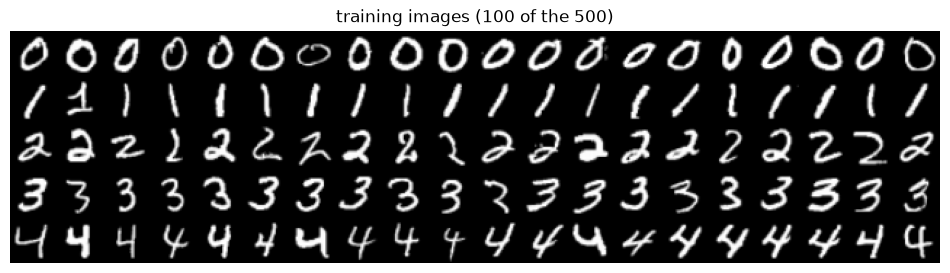

In [8]:
# One training image out of 5
examples = train_dataset.images[::5]

fig, ax = plt.subplots(figsize=(12, 3.2))
show_grid(ax, examples, 20, f"training images ({len(examples)} of the {len(train_dataset)})")
plt.show()

## 3. Model

`code/mymodel.py`

In [9]:
from mymodel import VAE

model = VAE().to(device)
num_parameters = sum(p.numel() for p in model.parameters())

print(model)
print(f"latent dimension     : {model.latent_dim}")
print(f"number of parameters : {num_parameters:,}")

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=400, bias=True)
    (2): ReLU()
  )
  (fc_mu): Linear(in_features=400, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=1024, bias=True)
    (3): Sigmoid()
  )
)
latent dimension     : 16
number of parameters : 840,256


In [10]:
# Check the interface of the model on a few images

x = test_dataset.images[:8].to(device)
latent_shape = (8, model.latent_dim)

with torch.no_grad():
    mu, logvar = model.encode(x)
    z = model.reparameterize(mu, logvar)
    x_hat = model.decode(z)
    outputs = model(x)

assert model.latent_dim >= 2, "latent_dim must be at least 2"
assert mu.shape == latent_shape, f"encode: mu has shape {tuple(mu.shape)}, expected {latent_shape}"
assert logvar.shape == latent_shape, f"encode: logvar has shape {tuple(logvar.shape)}, expected {latent_shape}"
assert z.shape == latent_shape, f"reparameterize: z has shape {tuple(z.shape)}, expected {latent_shape}"
assert x_hat.shape == x.shape, f"decode: x_hat has shape {tuple(x_hat.shape)}, expected {tuple(x.shape)}"
assert 0 <= x_hat.min() and x_hat.max() <= 1, "decode: the values of x_hat must be in [0, 1]"
assert len(outputs) == 3, "forward must return (x_hat, mu, logvar)"
assert outputs[0].shape == x.shape, "forward: the first output must be x_hat"
assert outputs[1].shape == outputs[2].shape == latent_shape, "forward: the last two outputs must be mu and logvar"

print("the model has the expected interface")

the model has the expected interface


## 4. Optimizer

`code/myoptim.py`

In [11]:
from myoptim import get_optimizer

optimizer = get_optimizer(model)

print(f"batch size       : {BATCH_SIZE}")
print(f"number of epochs : {NUM_EPOCHS}")
print(optimizer)

batch size       : 64
number of epochs : 100
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 5. Training

`code/mytrain.py`

In [12]:
from mytrain import train_one_epoch

history = {term: [] for term in LOSS_TERMS}

for epoch in range(1, NUM_EPOCHS + 1):
    losses = train_one_epoch(model, optimizer, train_loader, device)
    for term in LOSS_TERMS:
        history[term].append(float(losses[term]))

    if epoch == 1 or epoch == NUM_EPOCHS or epoch % max(1, NUM_EPOCHS // 20) == 0:
        print(f"epoch {epoch:4d}/{NUM_EPOCHS} | loss {losses['loss']:7.2f}"
              f" (recon {losses['recon']:7.2f}, kl {losses['kl']:6.2f})")

torch.save(model.state_dict(), TRAIN_DIR / "model.pt")

epoch    1/100 | loss  591.42 (recon  585.68, kl   5.73)
epoch    5/100 | loss  289.10 (recon  280.05, kl   9.05)
epoch   10/100 | loss  248.39 (recon  236.46, kl  11.92)
epoch   15/100 | loss  215.57 (recon  198.29, kl  17.28)
epoch   20/100 | loss  199.59 (recon  181.92, kl  17.67)
epoch   25/100 | loss  189.27 (recon  171.10, kl  18.17)
epoch   30/100 | loss  183.12 (recon  164.08, kl  19.03)
epoch   35/100 | loss  178.17 (recon  159.33, kl  18.85)
epoch   40/100 | loss  174.16 (recon  154.83, kl  19.34)
epoch   45/100 | loss  171.17 (recon  151.26, kl  19.91)
epoch   50/100 | loss  167.42 (recon  147.55, kl  19.88)
epoch   55/100 | loss  165.03 (recon  144.67, kl  20.36)
epoch   60/100 | loss  162.47 (recon  141.75, kl  20.72)
epoch   65/100 | loss  160.67 (recon  139.73, kl  20.95)
epoch   70/100 | loss  159.43 (recon  138.21, kl  21.22)
epoch   75/100 | loss  157.92 (recon  136.93, kl  20.98)
epoch   80/100 | loss  155.98 (recon  134.53, kl  21.44)
epoch   85/100 | loss  154.82 (

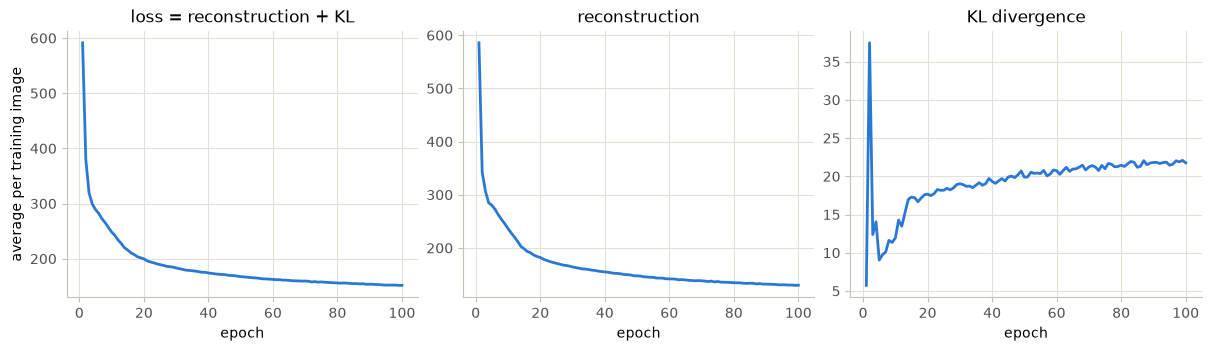

In [13]:
epochs = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)
for ax, (term, title) in zip(axes, LOSS_TERMS.items()):
    ax.plot(epochs, history[term], color=BLUE, linewidth=2)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    style_axes(ax)
axes[0].set_ylabel("average per training image")
save_figure(fig, TRAIN_DIR / "loss.png")

## 6. Sampling

`code/mysample.py`

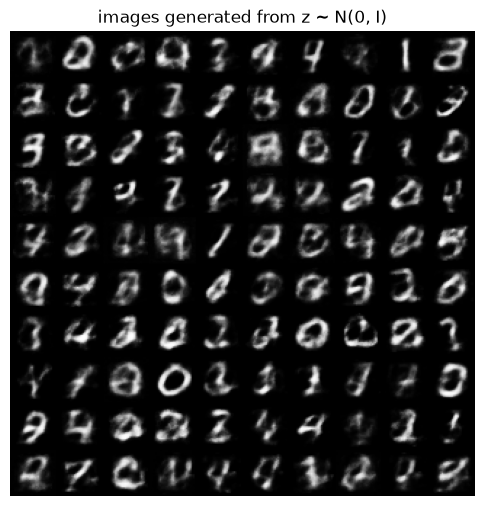

In [16]:
from mysample import sample

samples = sample(model, 100, device)

assert samples.shape == (100, *image_shape), f"sample: output has shape {tuple(samples.shape)}"
assert 0 <= samples.min() and samples.max() <= 1, "sample: the values must be in [0, 1]"

fig, ax = plt.subplots(figsize=(6, 6.3))
show_grid(ax, samples, 10, "images generated from z ~ N(0, I)")
save_figure(fig, SAMPLE_DIR / "sample.png")

## 7. Reconstruction

Test images and their reconstructions: each image is encoded, and the mean of `q(z|x)` is decoded.

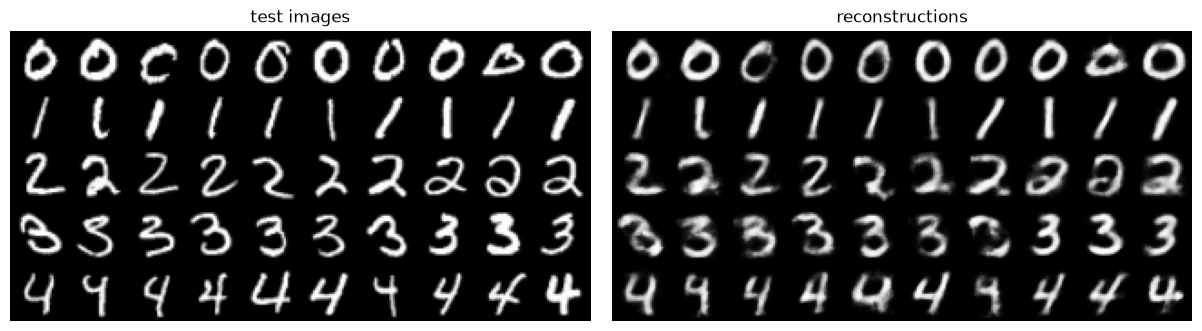

In [17]:
# One test image out of 100
originals = test_dataset.images[::100]

model.eval()
with torch.no_grad():
    mu, _ = model.encode(originals.to(device))
    reconstructions = model.decode(mu).cpu()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), constrained_layout=True)
show_grid(axes[0], originals, 10, "test images")
show_grid(axes[1], reconstructions, 10, "reconstructions")
save_figure(fig, RESULT_DIR / "reconstruction.png")

## 8. Results

`util/result.py` (provided) measures the trained model with the 5,000 test images. For both values, lower is better.

- **FID**: distance between the distribution of 5,000 images generated by the model and the distribution of the test images.
- **Reconstruction error**: squared difference between a test image and its reconstruction, summed over the pixels and averaged over the test images.

The first run downloads the network used by the FID (about 100 MB). The cell takes seconds with a GPU, but can take more than 10 minutes with a CPU.

In [18]:
from result import evaluate, save

result = evaluate(model)
result_file = save(result, info)

print(f"name                 : {info['name']}")
print(f"student ID           : {info['student_id']}")
print(f"batch size           : {BATCH_SIZE}")
print(f"number of epochs     : {NUM_EPOCHS}")
print(f"latent dimension     : {model.latent_dim}")
print(f"number of parameters : {num_parameters:,}")
print()
print(f"FID                  : {result['fid']:.2f}")
print(f"reconstruction error : {result['reconstruction_error']:.2f}")
print()
print(f"saved {result_file}")

/home/hong/class/neural-network/2026/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


name                 : Gildong Hong
student ID           : 20260000
batch size           : 64
number of epochs     : 100
latent dimension     : 16
number of parameters : 840,256

FID                  : 91.12
reconstruction error : 15.19

saved /nas2/users/hong/class/neural-network/2026/project/project-01/result/result_20260000_Gildong_Hong.csv
